# 04 – Pair-laps and target variable

**Goal:** Build the unit of analysis – a pair of consecutive cars in one lap – with the target `overtake` and the features known at the start of the lap; document every exclusion; first overtake rates per season and era.
**Input:** PostgreSQL tables `laps`, `results`, `races`, `weather` (notebook 03) · **Output:** table `pairs`, `data/processed/pairs.parquet`, `reports/logs/pairs_waterfall.csv`, figures in `reports/figures/`
**Assessment items:** P2 (documented exclusions), P3/B2 (SQL from Python), basis for P4–P7

**Definition.** For every lap *n* ≥ 2, car A on position *p* and car B on position *p*+1 at the end of lap *n*−1 form a pair. `overtake = 1` if B is ahead of A at the end of lap *n*. Only pairs with a gap ≤ 2.0 s at the start of lap *n* are analysed.

**Exclusion rules** (applied in this order, each rule counts what it removes):
1. no lap-*n* data for A or B (retirement, end of race for lapped cars, missing timing)
2. positions not consecutive at lap start
3. pit stop of A or B in lap *n* (positions change in the pit lane, not on track)
4. lap *n* neutralised (safety car, VSC, red flag)
5. restart lap (lap *n*−1 neutralised: cars are bunched up artificially)
6. missing timing / negative gap (inconsistent data)
7. gap > 2.0 s at lap start

**No leakage:** all features use information available at the start of lap *n*: order and gap at the end of lap *n*−1, tyres fitted for lap *n*, mean clean lap time of laps *n*−3 to *n*−1, qualifying, weather at lap start.

In [1]:
import sys
from pathlib import Path

# Make the repository root importable, whether Jupyter starts in the root or in notebooks/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import pandas as pd

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from src.build_pairs import build_pairs, run_from_db
from src.config import ERA_COLORS, ERA_LABELS, GAP_MAX, SEASONS
from src.db import get_engine
from src.viz import TEXT_SECONDARY, add_source, save, set_style

set_style()
engine = get_engine()

## 1. Build the pairs (read from and write to PostgreSQL)

In [3]:
pairs, waterfall = run_from_db(engine)
waterfall

,rule,removed,remaining
0,"candidate pair-laps (adjacent cars, laps 2..N)",0,197537
1,"no lap-n data for A or B (retirement, race end...",1973,195564
2,positions not consecutive at lap start (car mi...,0,195564
3,pit stop of A or B in lap n,20477,175087
4,"lap n neutralised (SC, VSC, red flag)",10169,164918
5,restart lap (lap n-1 neutralised),3540,161378
6,missing timing at lap start,0,161378
7,negative gap (inconsistent timing),0,161378
8,gap > 2.0 s at lap start,91182,70196


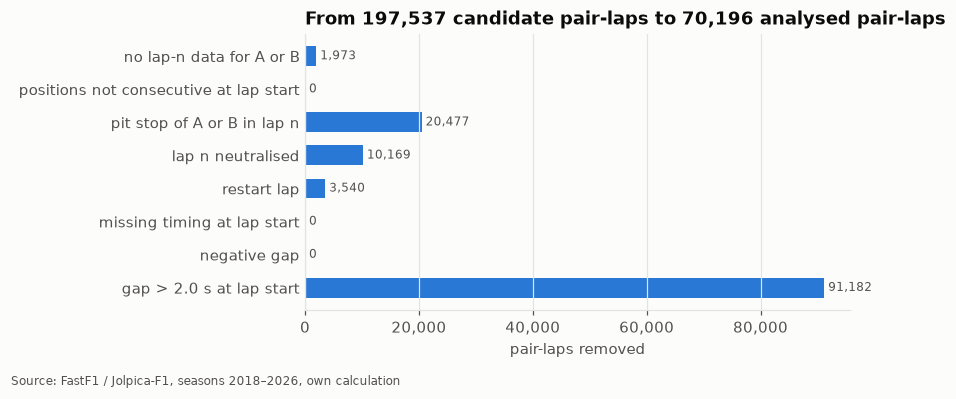

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
steps = waterfall.iloc[1:]
y = np.arange(len(steps))[::-1]
ax.barh(y, steps["removed"], color=ERA_COLORS["E1"], height=0.6)
ax.set_yticks(y, steps["rule"].str.replace(r" \(.*\)", "", regex=True))
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
for yi, v in zip(y, steps["removed"]):
    ax.text(v, yi, f" {v:,}", va="center", fontsize=8, color=TEXT_SECONDARY)
ax.set_xlabel("pair-laps removed")
ax.set_title(f"From {waterfall['remaining'].iloc[0]:,} candidate pair-laps to "
             f"{waterfall['remaining'].iloc[-1]:,} analysed pair-laps")
add_source(fig, f"FastF1 / Jolpica-F1, seasons {min(SEASONS)}–{max(SEASONS)}, "
                "own calculation")
fig.tight_layout(rect=(0, 0.04, 1, 1))
save(fig, "pairs_waterfall")
plt.show()

## 2. Target variable: overtake rate per season and era (SQL)

In [5]:
by_season = pd.read_sql("""
    SELECT r.season, r.era,
           COUNT(DISTINCT p.race_id) AS races,
           COUNT(*)                  AS pair_laps,
           SUM(p.overtake)           AS overtakes,
           ROUND(100.0 * AVG(p.overtake), 2) AS overtake_rate_pct
    FROM pairs p
    JOIN races r USING (race_id)
    GROUP BY r.season, r.era
    ORDER BY r.season
""", engine)
by_season

,season,era,races,pair_laps,overtakes,overtake_rate_pct
0,2018,E1,21,6885,528,7.67
1,2019,E1,21,7183,597,8.31
2,2020,E1,17,6127,445,7.26
3,2021,E1,22,7362,518,7.04
4,2022,E2,22,7753,681,8.78
5,2023,E2,22,8831,727,8.23
6,2024,E2,24,9367,695,7.42
7,2025,E2,24,10132,640,6.32
8,2026,E3,19,6556,631,9.62


In [6]:
pd.read_sql("""
    SELECT r.era,
           COUNT(DISTINCT p.race_id)         AS races,
           COUNT(*)                          AS pair_laps,
           SUM(p.overtake)                   AS overtakes,
           ROUND(100.0 * AVG(p.overtake), 2) AS overtake_rate_pct
    FROM pairs p
    JOIN races r USING (race_id)
    GROUP BY r.era
    ORDER BY r.era
""", engine)

,era,races,pair_laps,overtakes,overtake_rate_pct
0,E1,81,27557,2088,7.58
1,E2,92,36083,2743,7.60
2,E3,19,6556,631,9.62


The classes are strongly imbalanced (only a few percent of pair-laps end with an overtake). Accuracy is therefore not a suitable main metric for the models later; precision, recall and PR-AUC are.

## 3. Overtake rate by gap at lap start (SQL with `width_bucket`)

In [7]:
by_gap = pd.read_sql("""
    SELECT r.era,
           LEAST(width_bucket(p.gap_s, 0, 2.0, 8), 8) AS bucket,
           COUNT(*)        AS pair_laps,
           SUM(p.overtake) AS overtakes
    FROM pairs p
    JOIN races r USING (race_id)
    GROUP BY r.era, bucket
    ORDER BY r.era, bucket
""", engine)
by_gap["gap_mid_s"] = (by_gap["bucket"] - 0.5) * 0.25
by_gap["rate"] = by_gap["overtakes"] / by_gap["pair_laps"]

# 95 % Wilson confidence interval of a proportion
z = 1.96
n, phat = by_gap["pair_laps"], by_gap["rate"]
centre = (phat + z**2 / (2 * n)) / (1 + z**2 / n)
half = z * np.sqrt(phat * (1 - phat) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
by_gap["ci_low"], by_gap["ci_high"] = centre - half, centre + half
by_gap

,era,bucket,pair_laps,overtakes,gap_mid_s,rate,ci_low,ci_high
0,E1,1,576,293,0.125,0.508681,0.467931,0.549315
1,E1,2,1802,624,0.375,0.346282,0.324662,0.368556
2,E1,3,4613,702,0.625,0.152179,0.142103,0.162833
3,E1,4,5346,242,0.875,0.045267,0.040014,0.051174
4,E1,5,4577,114,1.125,0.024907,0.020775,0.029836
5,E1,6,4113,53,1.375,0.012886,0.009865,0.016816
6,E1,7,3594,35,1.625,0.009738,0.007011,0.013513
7,E1,8,2936,25,1.875,0.008515,0.005774,0.012540
8,E2,1,931,522,0.125,0.560687,0.528622,0.592254
9,E2,2,4386,1075,0.375,0.245098,0.232594,0.258048


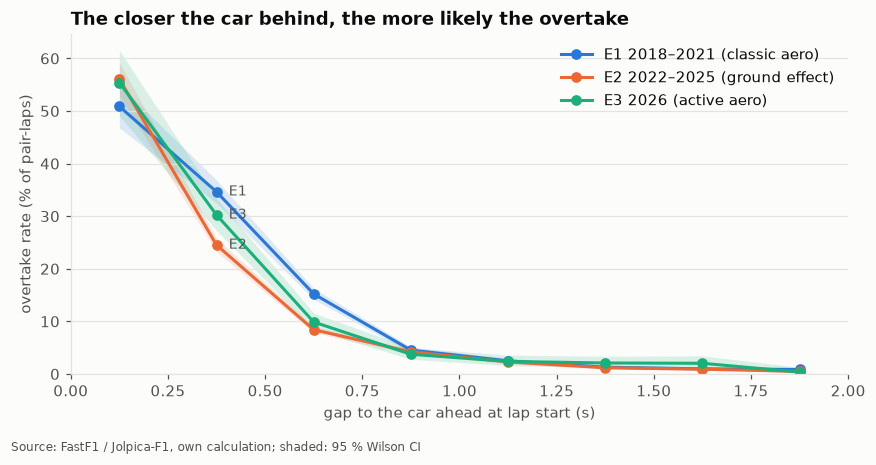

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for era, g in by_gap.groupby("era"):
    color = ERA_COLORS[era]
    ax.fill_between(g["gap_mid_s"], 100 * g["ci_low"], 100 * g["ci_high"],
                    color=color, alpha=0.15, linewidth=0)
    ax.plot(g["gap_mid_s"], 100 * g["rate"], marker="o", color=color,
            label=ERA_LABELS[era])
    second = g.iloc[1]  # lines are well separated at the second gap class
    ax.annotate(era, (second["gap_mid_s"], 100 * second["rate"]),
                xytext=(8, 0), textcoords="offset points", color=TEXT_SECONDARY,
                fontsize=9, va="center")
ax.set_xlim(0, GAP_MAX)
ax.set_ylim(bottom=0)
ax.set_xlabel("gap to the car ahead at lap start (s)")
ax.set_ylabel("overtake rate (% of pair-laps)")
ax.set_title("The closer the car behind, the more likely the overtake")
ax.legend(loc="upper right")
add_source(fig, "FastF1 / Jolpica-F1, own calculation; shaded: 95 % Wilson CI")
fig.tight_layout(rect=(0, 0.04, 1, 1))
save(fig, "overtake_rate_by_gap_era")
plt.show()

## 4. Sensitivity of the gap threshold

In [9]:
laps = pd.read_sql("""SELECT race_id, driver_id, lap_number, lap_time_s, time_end_s,
                                position, compound, tyre_life, pit_in, pit_out, track_status
                         FROM laps""", engine)
race_drivers = pd.read_sql("SELECT race_id, driver_id, team, quali_pos FROM results", engine)
races = pd.read_sql("SELECT race_id, era, total_laps FROM races", engine)

rows = []
for gap in (1.0, 1.5, 2.0, 3.0):
    p, _ = build_pairs(laps, race_drivers, races[["race_id", "total_laps"]], gap_max=gap)
    p = p.merge(races[["race_id", "era"]], on="race_id")
    for era, g in p.groupby("era"):
        rows.append({"gap_max_s": gap, "era": era, "pair_laps": len(g),
                     "overtake_rate_pct": round(100 * g["overtake"].mean(), 2)})
pd.DataFrame(rows).pivot(index="gap_max_s", columns="era",
                         values=["pair_laps", "overtake_rate_pct"])

pair_laps                  overtake_rate_pct              
era              E1       E2      E3                E1     E2     E3
gap_max_s                                                           
1.0         12358.0  19749.0  3668.0             15.08  12.83  15.76
1.5         21038.0  28685.0  5353.0              9.64   9.38  11.51
2.0         27557.0  36083.0  6556.0              7.58   7.60   9.62
3.0         36141.0  46392.0  8340.0              5.90   5.98   7.76

## 5. Why pit-stop laps are excluded (SQL with window functions)

The query below rebuilds the candidate pairs directly in SQL – `LAG()` over the running order of each lap – and compares green-flag pair-laps (gap ≤ 2 s) with and without a pit stop. If a pit stop is involved, the order at the line changes in most cases, because the car in the pit lane loses time, not because it was overtaken on track.

In [10]:
pd.read_sql("""
    WITH start AS (
        SELECT race_id,
               lap_number + 1                AS lap,
               driver_id                     AS car_b,
               position                      AS pos_b_start,
               time_end_s                    AS t_b,
               LAG(driver_id)  OVER w        AS car_a,
               LAG(position)   OVER w        AS pos_a_start,
               LAG(time_end_s) OVER w        AS t_a
        FROM laps
        WHERE position IS NOT NULL
        WINDOW w AS (PARTITION BY race_id, lap_number ORDER BY position)
    ),
    pair_laps AS (
        SELECT s.t_b - s.t_a                               AS gap_s,
               s.pos_b_start - s.pos_a_start               AS pos_diff,
               lb.position < la.position                   AS order_swapped,
               la.pit_in OR la.pit_out OR lb.pit_in OR lb.pit_out AS pit_stop,
               la.track_status ~ '[4567]' OR lb.track_status ~ '[4567]' AS neutralised
        FROM start s
        JOIN laps la ON la.race_id = s.race_id AND la.driver_id = s.car_a AND la.lap_number = s.lap
        JOIN laps lb ON lb.race_id = s.race_id AND lb.driver_id = s.car_b AND lb.lap_number = s.lap
        WHERE s.car_a IS NOT NULL
    )
    SELECT CASE WHEN pit_stop THEN 'pit stop of A or B in lap n' ELSE 'no pit stop' END AS lap_type,
           COUNT(*)                                       AS pair_laps,
           SUM(order_swapped::int)                        AS order_swaps,
           ROUND(100.0 * AVG(order_swapped::int), 1)      AS swap_rate_pct
    FROM pair_laps
    WHERE NOT neutralised AND gap_s BETWEEN 0 AND 2.0 AND pos_diff = 1
    GROUP BY 1
    ORDER BY 1
""", engine)

,lap_type,pair_laps,order_swaps,swap_rate_pct
0,no pit stop,72800,5773,7.9
1,pit stop of A or B in lap n,6415,3268,51.0


## 6. Known limitation: only the order at the line counts

The target uses the order at the end of each lap. Two cases stay invisible:
- **Overtaken and re-overtaken within one lap**, e.g. Bahrain 2021, lap 53 (Verstappen passed Hamilton and had to give the position back) or Bahrain 2022, laps 17–18 (Leclerc and Verstappen swapped twice per lap).
- **On-track overtake in a lap in which one car pits.** Spain 2021, lap 60: Hamilton passed Verstappen for the lead, and Verstappen pitted at the end of that lap, so the pair-lap is removed by rule 3.

In [11]:
pd.read_sql("""
    SELECT lap_number, driver_id, position, ROUND(time_end_s, 3) AS time_end_s,
           pit_in, pit_out, compound, tyre_life
    FROM laps
    WHERE race_id = 202104 AND lap_number BETWEEN 59 AND 61
      AND driver_id IN ('hamilton', 'max_verstappen')
    ORDER BY lap_number, position
""", engine)

,lap_number,driver_id,position,time_end_s,pit_in,pit_out,compound,tyre_life
0,59,max_verstappen,1,7012.968,False,False,MEDIUM,35
1,59,hamilton,2,7013.528,False,False,MEDIUM,23
2,60,hamilton,1,7095.733,False,False,MEDIUM,24
3,60,max_verstappen,2,7101.416,True,False,MEDIUM,36
4,61,hamilton,1,7176.840,False,False,MEDIUM,25
5,61,max_verstappen,2,7202.754,False,True,SOFT,1
